In [26]:

import os

print("Current folder:", os.getcwd())
print("Files in current folder:", os.listdir())


Current folder: /content
Files in current folder: ['.config', '.ipynb_checkpoints', 'sample_data', 'simulated_sales_data.csv']


In [27]:

from google.colab import files

uploaded = files.upload()


In [28]:

import pandas as pd

df = pd.read_csv("simulated_sales_data.csv")
df["Revenue"] = df["Quantity"] * df["Price"]

print(df.head())
print("Dataset size:", df.shape)


         Date          Product  Quantity  Price  Revenue
0  2026-09-01     External SSD         1    140      140
1  2026-09-01           Webcam         2     80      160
2  2026-09-02           Laptop         3   1200     3600
3  2026-09-02        USB Cable         2     10       20
4  2026-09-03  Docking Station         5    180      900
Dataset size: (120, 5)


In [29]:

import pandas as pd

# 1. Load the CSV dataset
df = pd.read_csv("simulated_sales_data.csv")

# 2. Create a Revenue column
df["Revenue"] = df["Quantity"] * df["Price"]

# 3. Preview the dataset
print("DATA PREVIEW")
print(df.head())

print("\nDataset size:", df.shape)

# 4. Calculate total revenue
total_revenue = df["Revenue"].sum()
print(f"\nTotal revenue: ${total_revenue:,.2f}")

# 5. Calculate revenue for each product
revenue_by_product = df.groupby("Product")["Revenue"].sum()
print("\nRevenue by product:")
print(revenue_by_product)

# 6. Find the product with the highest total revenue
top_product = revenue_by_product.idxmax()
top_revenue = revenue_by_product.max()
print(f"\nTop product by revenue: {top_product}")
print(f"Revenue from this product: ${top_revenue:,.2f}")

# 7. Calculate total quantity sold for each product
quantity = df.groupby("Product")["Quantity"].sum()
print("\nQuantity sold by product:")
print(quantity)

# 8. Find the product with the highest total quantity sold
top_quantity_product = quantity.idxmax()
max_quantity = quantity.max()
print(f"\nTop product by quantity: {top_quantity_product}")
print(f"Units sold: {max_quantity}")

# 9. Calculate daily revenue
daily_revenue = df.groupby("Date")["Revenue"].sum()
print("\nDaily revenue:")
print(daily_revenue)


DATA PREVIEW
         Date          Product  Quantity  Price  Revenue
0  2026-09-01     External SSD         1    140      140
1  2026-09-01           Webcam         2     80      160
2  2026-09-02           Laptop         3   1200     3600
3  2026-09-02        USB Cable         2     10       20
4  2026-09-03  Docking Station         5    180      900

Dataset size: (120, 5)

Total revenue: $86,625.00

Revenue by product:
Product
Docking Station     5760
External SSD        6720
Headphones          5500
Keyboard            2025
Laptop             50400
Laptop Stand        2205
Monitor            11400
Mouse                825
USB Cable            270
Webcam              1520
Name: Revenue, dtype: int64

Top product by revenue: Laptop
Revenue from this product: $50,400.00

Quantity sold by product:
Product
Docking Station    32
External SSD       48
Headphones         55
Keyboard           27
Laptop             42
Laptop Stand       49
Monitor            38
Mouse              33
USB Ca

In [30]:

# Check for missing values
print("Missing values:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())


Missing values:
Date        0
Product     0
Quantity    0
Price       0
Revenue     0
dtype: int64

Number of duplicate rows: 4


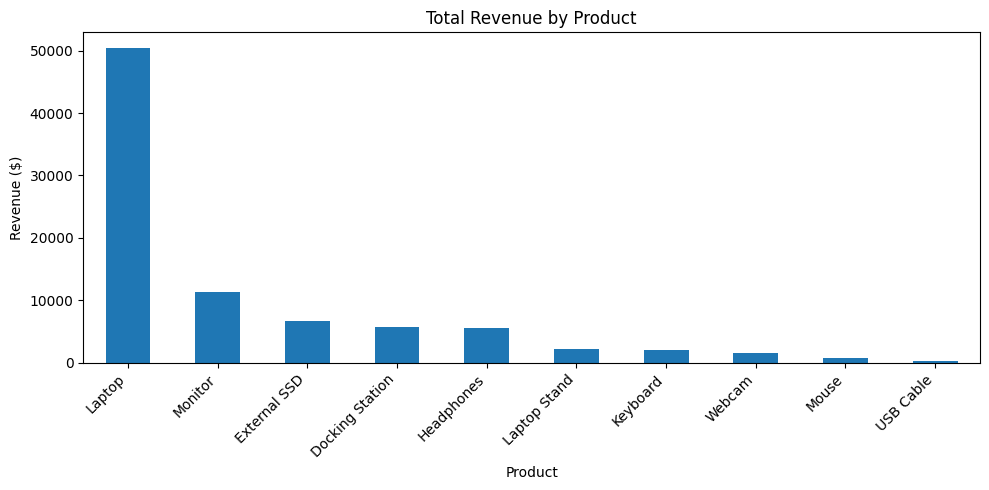

In [31]:

import matplotlib.pyplot as plt

revenue_by_product = df.groupby("Product")["Revenue"].sum()
revenue_by_product = revenue_by_product.sort_values(ascending=False)

revenue_by_product.plot(kind="bar", figsize=(10, 5))

plt.title("Total Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


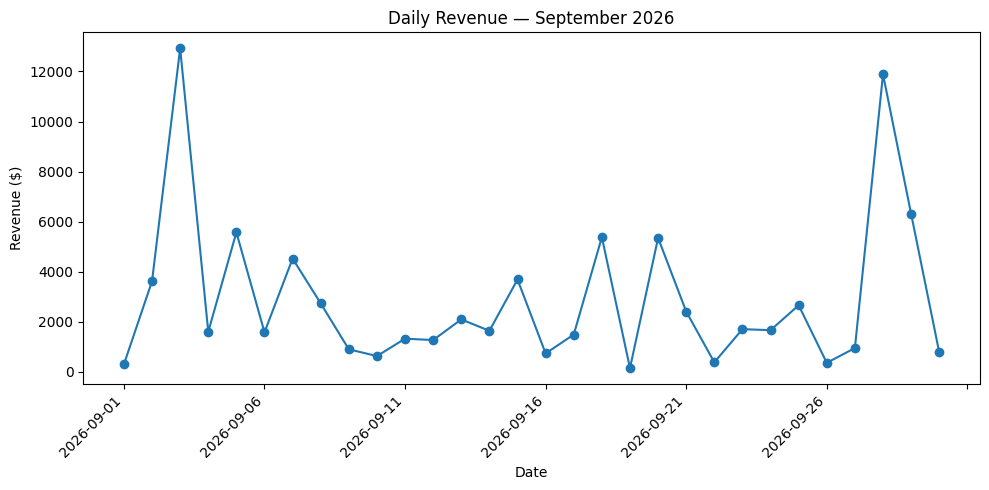

In [32]:

daily_revenue = df.groupby("Date")["Revenue"].sum()

daily_revenue.plot(kind="line", marker="o", figsize=(10, 5))

plt.title("Daily Revenue — September 2026")
plt.xlabel("Date")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [33]:
df.to_csv("sales_with_revenue.csv", index=False)

In [34]:
from google.colab import files
files.download("sales_with_revenue.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
import sqlite3

connection = sqlite3.connect("sales.db")

df.to_sql("sales", connection, if_exists="replace", index=False)

print("SQL database ready!")

SQL database ready!


In [36]:
query = """
SELECT *
FROM sales;
"""

result = pd.read_sql_query(query, connection)
print(result.head())

         Date          Product  Quantity  Price  Revenue
0  2026-09-01     External SSD         1    140      140
1  2026-09-01           Webcam         2     80      160
2  2026-09-02           Laptop         3   1200     3600
3  2026-09-02        USB Cable         2     10       20
4  2026-09-03  Docking Station         5    180      900


In [37]:
query = """
SELECT SUM(Revenue) AS total_revenue
FROM sales;
"""
result = pd.read_sql_query(query, connection)
print(result)

   total_revenue
0          86625


In [38]:
query = """
SELECT Product, SUM(Revenue) AS total_revenue
FROM sales
GROUP BY Product
ORDER BY total_revenue DESC;
"""
result = pd.read_sql_query(query, connection)
print(result)

           Product  total_revenue
0           Laptop          50400
1          Monitor          11400
2     External SSD           6720
3  Docking Station           5760
4       Headphones           5500
5     Laptop Stand           2205
6         Keyboard           2025
7           Webcam           1520
8            Mouse            825
9        USB Cable            270


In [39]:
query = """
SELECT Product, SUM(Quantity) AS units_sold
FROM sales
GROUP BY Product
ORDER BY units_sold DESC;
"""
result = pd.read_sql_query(query, connection)
print(result)

           Product  units_sold
0       Headphones          55
1     Laptop Stand          49
2     External SSD          48
3           Laptop          42
4          Monitor          38
5            Mouse          33
6  Docking Station          32
7        USB Cable          27
8         Keyboard          27
9           Webcam          19


In [40]:
query = """
SELECT Date, SUM(Revenue) AS daily_revenue
FROM sales
GROUP BY Date
ORDER BY Date;
"""
result = pd.read_sql_query(query, connection)
print(result)

          Date  daily_revenue
0   2026-09-01            300
1   2026-09-02           3620
2   2026-09-03          12925
3   2026-09-04           1600
4   2026-09-05           5575
5   2026-09-06           1580
6   2026-09-07           4525
7   2026-09-08           2735
8   2026-09-09            900
9   2026-09-10            630
10  2026-09-11           1325
11  2026-09-12           1270
12  2026-09-13           2095
13  2026-09-14           1640
14  2026-09-15           3690
15  2026-09-16            735
16  2026-09-17           1490
17  2026-09-18           5380
18  2026-09-19            150
19  2026-09-20           5350
20  2026-09-21           2410
21  2026-09-22            380
22  2026-09-23           1705
23  2026-09-24           1665
24  2026-09-25           2660
25  2026-09-26            360
26  2026-09-27            950
27  2026-09-28          11890
28  2026-09-29           6310
29  2026-09-30            780
